# **1. Problem Description**

From a data set of fictitious sports betting customers there is
a business need to understand which customers are more likely to be *VIPs*, so
that these customers will be target in priority with a new specific offer next month.
Please use the data made available in the VIP Train.csv spreadsheet to train a
predictive model to provide your best answer to this business problem.

The training set (Train.csv) contains 8 features and one binary target variable named VIP, this set is going to be used to train a predictive model. Then the model predicted is going to be apply in the *Test.csv* spreadsheet to insert the predicted probability that a customer will become a VIP in the column VIP.

The primary evaluation metric will be the Log Loss.

Please explain the modelling approach you have taken and give a brief
overview of your code during the interview. The total time for the presen-
tation should be about 20 minutes.

Log Loss definition:

$L(y, p) = −(ylog(p) + (1 − y)log(1 − p))$

Please send back within seven days the following:
- Test set predictions
- Code used
- Presentation


# **2. Descriptive analysis**


## **2.1 Set up environment**

Install and import libraries

In [ ]:
!pip install scikit-plot

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import re
import os
import pickle
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder

import seaborn as sns
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc
import scipy.stats as st

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb

import scikitplot as skplt
import itertools
import requests
from google.colab import drive
# mount google drive information in a google colaboratory directory
drive.mount('/content/gdrive')

Mounted at /content/gdrive


Use of functions

In [ ]:
#functions
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Greens):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title, fontsize=16)

    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()


def Find_Optimal_Cutoff(target, predicted):
    """ Find the optimal probability cutoff point for a classification model related to event rate
    Parameters
    ----------
    target : Matrix with dependent or target data, where rows are observations

    predicted : Matrix with predicted data, where rows are observations

    Returns
    -------
    list type, with optimal cutoff value

    """
    fpr, tpr, threshold = roc_curve(target, predicted)
    i = np.arange(len(tpr))
    roc = pd.DataFrame({'tf' : pd.Series(tpr-(1-fpr), index=i), 'threshold' : pd.Series(threshold, index=i)})
    roc_t = roc.iloc[(roc.tf-0).abs().argsort()[:1]]

    return list(roc_t['threshold'])

Read data

In [ ]:
path = r'gdrive/My Drive/gamblingCompany - Data Scientist/Data/' # path

df_model = pd.read_csv(path+'VIP_Train.csv', na_values='?')
df_deploy = pd.read_csv(path+'VIP_Test.csv', na_values='?')

Check that both dataframes have the same structure

In [ ]:
df_model.head()

,Player_Id,Deposit_Amount,Deposit_Quantity,Deposit_Method,Age,Country,Gender,Dim_Alert_Type_Desc,VIP
0,613972,30.173168,5,v3_ebs,31.0,RO,NaN,All Deposit,0
1,1001159,4871.409870,1,instadebitviasc,30.0,VG,F,All Deposit,0
2,2405146,37.812566,3,ifund-smooth-usd,21.0,LB,M,Special,0
3,3694261,52.722560,15,diners,33.0,NZ,M,Sign Up,0
4,7004960,42.776558,3,lateralpayments,55.0,IR,M,All Deposit,0


In [ ]:
df_deploy.head()

,Player_Id,Deposit_Amount,Deposit_Quantity,Deposit_Method,Age,Country,Gender,Dim_Alert_Type_Desc,VIP
0,5890355,44.313120,20,debitcard,31.0,GP,M,First_Deposit,0.0
1,940061,56.223226,1,servipag,52.0,KM,NaN,Special,0.0
2,8549083,28.329851,13,visadebit,42.0,LK,F,NaN,0.0
3,7447056,0.000000,0,lateralpayments,33.0,IR,M,Special,0.0
4,7047755,0.000000,0,payr,29.0,MY,M,Special,0.0


The structure in both dataset is the same.



In [ ]:
print('Table Model - Structure:')
print(df_model.dtypes)
print(' ')
print('Table Deliverable - Structure:')
print(df_deploy.dtypes)

Table Model - Structure:
Player_Id                int64
Deposit_Amount         float64
Deposit_Quantity         int64
Deposit_Method          object
Age                    float64
Country                 object
Gender                  object
Dim_Alert_Type_Desc     object
VIP                      int64
dtype: object
 
Table Deliverable - Structure:
Player_Id                int64
Deposit_Amount         float64
Deposit_Quantity         int64
Deposit_Method          object
Age                    float64
Country                 object
Gender                  object
Dim_Alert_Type_Desc     object
VIP                    float64
dtype: object


Check that all the categorical columns in the deliverable set are contained in the model set

In [ ]:
# List1
List1 = list(df_model.Country.unique())

# List2
List2 = list(df_deploy.Country.unique())

check_countries =  all(item in List1 for item in List2)
check_countries

True

In [ ]:
# List1
List1 = list(df_model.Deposit_Method.unique())

# List2
List2 = list(df_deploy.Deposit_Method.unique())

check_Deposit_Method =  all(item in List1 for item in List2)
check_Deposit_Method

True

In [ ]:
# List1
List1 = list(df_model.Dim_Alert_Type_Desc.unique())

# List2
List2 = list(df_deploy.Dim_Alert_Type_Desc.unique())

check_Dim_Alert_Type_Desc =  all(item in List1 for item in List2)
check_Dim_Alert_Type_Desc

True

In [ ]:
# List1
List1 = list(df_model.Gender.unique())

# List2
List2 = list(df_deploy.Gender.unique())

check_Gender =  all(item in List1 for item in List2)
check_Gender

True

There are no new categories in the deliverable dataset

Check if any player id from the deliverable dataset is in the model dataset.

In [ ]:
# List1
List1 = list(df_model.Player_Id.unique())

# List2
List2 = list(df_deploy.Player_Id.unique())

check_players =  any(item in List1 for item in List2)
check_players

False

In [ ]:
df_model.Player_Id.nunique()

35000

In [ ]:
player_id = df_model.Player_Id
df_model.drop(columns=['Player_Id'],inplace=True)

There are no players in the deliverable dataset included in the Model set. Also, there are no repeated players in the dataset.

## **2.2.Categorical's variables descriptive analysis**
The only dataset used in the next step is the Model dataset, which is the dataset used for the data analysis.

With the *count* field in the descriptive table and the amount of rows, we can figure out the number of missing data. Missing data is not a big issue in the Deposit method and country. We have some issues with gender and Alert type.

**Hipothesis**: if a person doesn't have any data about country or gender, this is because the person is not registered in a proper way, and this is needed for a deposit. So, if a person is not properly registered and the hipothesis is true, it could be assumed that this person is not VIP.

In [ ]:
descriptive_table = df_model.describe(include='all').round(decimals=3)
description_object=descriptive_table.loc[['count','unique','top','freq']]
description_object.dropna(axis=1, thresh=None, inplace=True)
description_object

,Deposit_Method,Country,Gender,Dim_Alert_Type_Desc
count,34669,34647,31173,28909
unique,154,195,2,5
top,servipag,MT,F,Sign Up
freq,271,218,15666,5860


In [ ]:
print('Amount of rows: '+str(df_model.shape[0]))

Amount of rows: 35000


**Gender:**

In [ ]:
pd.value_counts(df_model.Gender,dropna=False)

F      15666
M      15507
NaN     3827
Name: Gender, dtype: int64

The % of VIP customer is similar over different gender

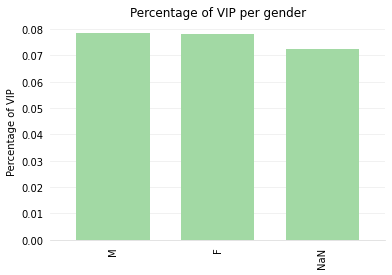

In [ ]:
cmap = plt.get_cmap('Spectral')
colors = [cmap(i) for i in np.linspace(0, 1, 8)]
fig, ax = plt.subplots()

df_model.fillna('NaN').groupby(['Gender'])['VIP'].mean().sort_values(ascending=False).plot(kind="bar", color=colors[5], width=.7)
plt.title("Percentage of VIP per gender")
plt.xlabel("")
plt.ylabel("Percentage of VIP")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')

# Second, remove the ticks as well.
ax.tick_params(bottom=False, left=False)

# Third, add a horizontal grid (but keep the vertical grid hidden).
# Color the lines a light gray as well.
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

**Alert Type:**

In [ ]:
pd.value_counts(df_model.Dim_Alert_Type_Desc,dropna=False)

NaN              6091
Sign Up          5860
Special          5835
First_Deposit    5795
Re-deposit       5726
All Deposit      5693
Name: Dim_Alert_Type_Desc, dtype: int64

The % of VIP customer is similar over different alert types. in the next steps alert types is going to be group in “sign ups / first deposit” and “rest”.

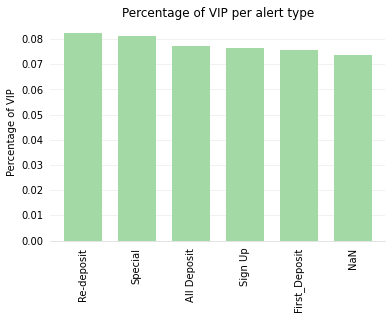

In [ ]:
fig, ax = plt.subplots()
df_model.fillna('NaN').groupby(['Dim_Alert_Type_Desc'])['VIP'].mean().sort_values(ascending=False).plot(kind="bar", color=colors[5], width=.7)
plt.title("Percentage of VIP per alert type")
plt.xlabel("")
plt.ylabel("Percentage of VIP")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')

# Second, remove the ticks as well.
ax.tick_params(bottom=False, left=False)

# Third, add a horizontal grid (but keep the vertical grid hidden).
# Color the lines a light gray as well.
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

**Country:** as it can be seen in the next chart, the difference in percentage of VIP clients is noticeable across the countries.

In [ ]:
pd.value_counts(df_model.Country,dropna=False)

NaN    353
MT     218
HN     212
DJ     207
EG     206
      ... 
EU     151
GA     148
AZ     146
BG     146
UA     141
Name: Country, Length: 196, dtype: int64

In [ ]:
fig, ax = plt.subplots(figsize=(18, 6))

plt.subplot(1,2, 1)
df_model.fillna('NaN').groupby(['Country'])['VIP'].mean().sort_values()[-10:].plot(kind="barh", color=colors[5], width=.7)
plt.xlim(0,0.25)
plt.title("Percentage of VIP per country code - Top 10")
plt.ylabel("")
plt.xlabel("Percentage of VIP")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')

# Second, remove the ticks as well.
ax.tick_params(bottom=False, left=False)

# Third, add a horizontal grid (but keep the vertical grid hidden).
# Color the lines a light gray as well.
ax.set_axisbelow(True)
ax.xaxis.grid(True, color='#EEEEEE')
ax.yaxis.grid(False);


plt.subplot(1,2, 2)
df_model.fillna('NaN').groupby(['Country'])['VIP'].mean().sort_values()[0:10].plot(kind="barh", color=colors[5], width=.7)
plt.xlim(0,0.25)
plt.title("Percentage of VIP per country code - Last 10")
plt.ylabel("")
plt.xlabel("Percentage of VIP")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')

# Second, remove the ticks as well.
ax.tick_params(bottom=False, left=False)

# Third, add a horizontal grid (but keep the vertical grid hidden).
# Color the lines a light gray as well.
ax.set_axisbelow(True)
ax.xaxis.grid(True, color='#EEEEEE')
ax.yaxis.grid(False);

NameError: ignored

**Deposit Method:** as it can be seen in the next tables, the difference in percentage of VIP clients is high accross the different deposit methods.

In [ ]:
pd.value_counts(df_model.Deposit_Method, dropna=False)

NaN                 331
servipag            271
ebs-3d-smooth       263
maestro             262
macaucashdesk       255
                   ... 
sc-gvccashier       200
gvcser3dtrx         194
pgclubcashier       194
gvcserregulartrx    192
cqr_banktransfer    181
Name: Deposit_Method, Length: 155, dtype: int64

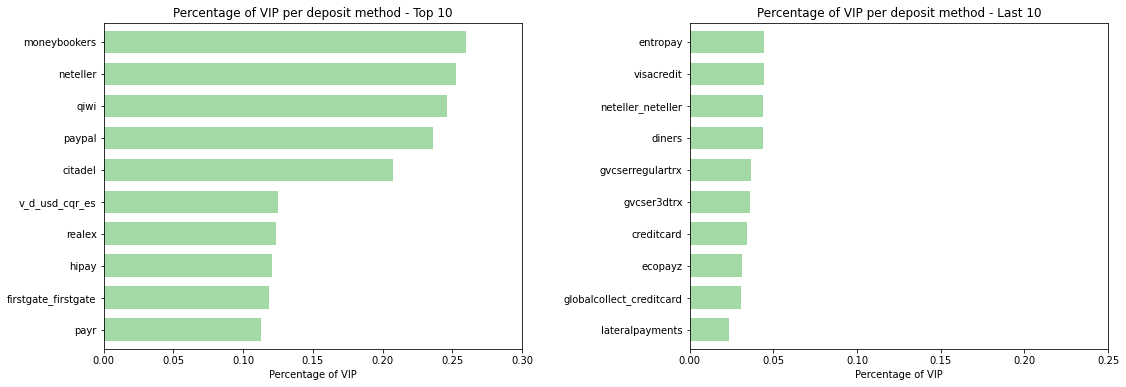

In [ ]:
f,ax=plt.subplots(figsize=(18,6))

plt.subplot(1,2, 1)
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=None)
df_model.fillna('NaN').groupby(['Deposit_Method'])['VIP'].mean().sort_values()[-10:].plot(kind="barh", color=colors[5], width=.7)
plt.xlim(0,0.3)
plt.title("Percentage of VIP per deposit method - Top 10")
plt.ylabel("")
plt.xlabel("Percentage of VIP")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')

# Second, remove the ticks as well.
ax.tick_params(bottom=False, left=False)

# Third, add a horizontal grid (but keep the vertical grid hidden).
# Color the lines a light gray as well.
ax.set_axisbelow(True)
ax.xaxis.grid(True, color='#EEEEEE')
ax.yaxis.grid(False)


plt.subplot(1,2, 2)
plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=None)
df_model.fillna('NaN').groupby(['Deposit_Method'])['VIP'].mean().sort_values()[0:10].plot(kind="barh", color=colors[5], width=.7)
plt.xlim(0,0.25)
plt.title("Percentage of VIP per deposit method - Last 10")
plt.ylabel("")
plt.xlabel("Percentage of VIP")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')

# Second, remove the ticks as well.
ax.tick_params(bottom=False, left=False)

# Third, add a horizontal grid (but keep the vertical grid hidden).
# Color the lines a light gray as well.
ax.set_axisbelow(True)
ax.xaxis.grid(True, color='#EEEEEE')
ax.yaxis.grid(False);

**Rejected Hipothesis**: The hipothesis (just with descriptive data, without a statistical test)  "*If a person doesn't have data about country or gender is because the person is not register in properly, and this is needed for a deposit"* is not true, so we can't set up as non VIP people without a country assigned.

In this session it can be observed that the dataset doesn't have small categories (categories with less than 30 clients tends to overfit the final model), so use the "other" category is not needed.

**Replace Missing values**:
Some classification techniques don't work with missing data.

In [ ]:
df_model.Gender.fillna('NaN', inplace=True)
df_model.Dim_Alert_Type_Desc.fillna('NaN', inplace=True)
df_model.Country.fillna('NaN', inplace=True)
df_model.Deposit_Method.fillna('NaN', inplace=True)

## **2.3.Data Enrichment**

**Gross Domestic Product (GDP) Table:**

Gross Domestic Product (GDP) per capita shows a country's GDP divided by its total population. The table below lists countries in the world ranked by GDP at Purchasing Power Parity (PPP) per capita, along with the Nominal GDP per capita. PPP takes into account the relative cost of living, rather than using only exchange rates, therefore providing a more accurate picture of the real differences in income.

Info from: https://www.worldometers.info/gdp/gdp-per-capita/

In [ ]:
url = 'https://www.worldometers.info/gdp/gdp-per-capita/'
html = requests.get(url).content
GDP_list = pd.read_html(html)
GDP = GDP_list[-1]
GDP.rename(columns={'#':'Ranking_GDP'}, inplace=True)
GDP.head()

NameError: ignored

In [ ]:
GDP=GDP[['Ranking_GDP','Country','GDP (nominal) per capita (2017)']]
GDP.rename(columns={'GDP (nominal) per capita (2017)':'GDP_value','Country':'Country_name'}, inplace=True)

GDP['GDP_value'] =GDP['GDP_value'].apply(lambda x: float(x.replace(',', '').replace('$', '')))

In [ ]:
GDP.head()

**Country codes Table:**
This is used to merge the initial data set and the GDP dataset. Also for future interpretations.

In [ ]:
url = 'https://www.iban.com/country-codes'
html = requests.get(url).content
Country_codes = pd.read_html(html)
Country_codes = Country_codes[-1]
Country_codes.rename(columns={'Alpha-2 code':'Code','Country':'Country_name'}, inplace=True)
Country_codes.drop(columns=['Alpha-3 code',	'Numeric'],inplace=True)
print('Country code table shape: '+ str(Country_codes.shape))
Country_codes.head()

Delete all the "()" in the country name field, for example "Bolivia (Plurinational State of)" was change by "Bolivia"

In [ ]:
Country_codes['Country_name']=Country_codes.Country_name.apply(lambda x: re.sub("[\(\[].*?[\)\]]", "", x))
Country_codes['Country_name']=Country_codes.Country_name.apply(lambda x: x[:-1] if x[-1]==' ' else x)

Save dataset in a pickle file: This step is made because this data is going to be used in the model deploy. in a pickle file the user can save python objects in different format and read then without problems


In [ ]:
with open(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs/Country_codes.pkl', 'wb') as f:
    pickle.dump(Country_codes, f)

with open(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs/GDP.pkl', 'wb') as f:
    pickle.dump(GDP, f)

Merge databases:

In [ ]:
df_model = pd.merge(df_model,Country_codes,  how='left', left_on=['Country'], right_on = ['Code'])
df_model.rename(columns={'Country':'Country_code'}, inplace=True)
df_model.drop(columns=['Code'],inplace=True)

In [ ]:
df_model.head()

In [ ]:
df_model = pd.merge(df_model, GDP,  how='left', left_on=['Country_name'], right_on = ['Country_name'])

Median is used as a metric to fill the na data derived from the merge between tables, this is a centrality measure like the average but it is robust to outliers.

In [ ]:
df_model.GDP_value.fillna((GDP.GDP_value.median()),inplace=True)
df_model.Ranking_GDP.fillna((round(GDP.Ranking_GDP.median(),0)),inplace=True)

## **2.4. Numeric's variables descriptive analysis**
From the descriptive table, it can be concluded that Deposit_amount, Deposit_quantity and VIP don't have missing data. Age have less than 400 missings (1% more or less) and the min and max values looks coherent.

In [ ]:
descriptive_table = df_model[['Deposit_Amount','Deposit_Quantity','Age','VIP','Ranking_GDP',	'GDP_value']].describe(include='all').round(decimals=3)
description_numeric = descriptive_table.loc[['count','mean','std','min','25%','50%','75%','max']]
description_numeric.dropna(axis=1, thresh=None, inplace=True)
description_numeric

,Deposit_Amount,Deposit_Quantity,Age,VIP,Ranking_GDP,GDP_value
count,35000.000,35000.000,34641.000,35000.000,35000.000,35000.000
mean,170.429,5.358,33.451,0.078,91.455,12980.925
std,931.817,9.022,8.726,0.268,46.661,17902.844
min,0.000,0.000,18.000,0.000,1.000,293.000
25%,28.711,1.000,27.000,0.000,56.000,3762.000
50%,43.944,2.000,33.000,0.000,96.000,5765.000
75%,57.365,4.000,39.000,0.000,117.000,14364.000
max,10085.205,62.000,73.000,1.000,190.000,105280.000


In [ ]:
print('Amount of rows: '+str(df_model.shape[0]))

Amount of rows: 35000


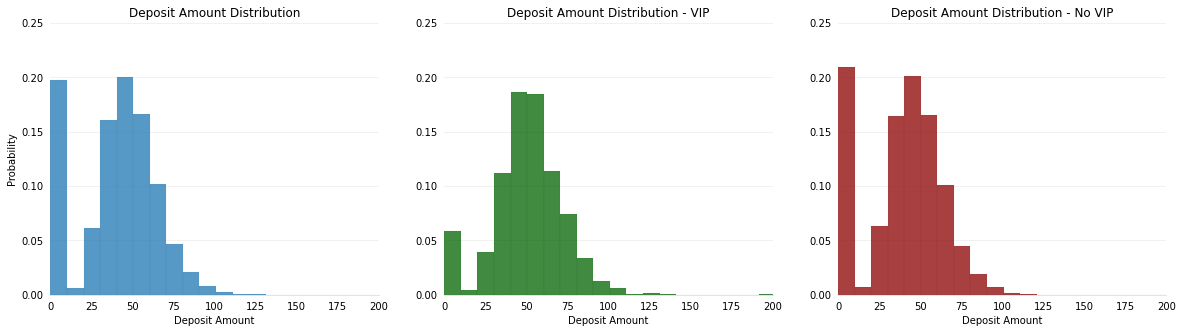

In [ ]:
f,ax=plt.subplots(figsize=(20,5))

plt.subplot(1,3, 1)
ax=sns.histplot(df_model.Deposit_Amount, bins=1000,stat="probability")
ax.set_xlim(0,200)
ax.set_ylim(0,0.25)
ax.set_title('Deposit Amount Distribution')
ax.set_xlabel('Deposit Amount')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);


plt.subplot(1,3, 2)
ax=sns.histplot(df_model[df_model.VIP==1].Deposit_Amount, bins=1000,color='darkgreen',stat="probability")
ax.set_xlim(0,200)
ax.set_ylim(0,0.25)
ax.set_ylabel(' ')
ax.set_xlabel('Deposit Amount')
ax.set_title('Deposit Amount Distribution - VIP')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

plt.subplot(1,3,3)
ax=sns.histplot(df_model[df_model.VIP==0].Deposit_Amount, bins=1000,color='darkred',stat="probability")
ax.set_xlim(0,200)
ax.set_ylim(0,0.25)
ax.set_ylabel(' ')
ax.set_xlabel('Deposit Amount')
ax.set_title('Deposit Amount Distribution - No VIP')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

The deposit amount between VIP and Non VIP is more or less the same. However, the percentage of Non VIP players with a small deposit is higher.

In [ ]:
print('Deposit Amount  - No VIP:')
print(df_model[df_model.VIP==0].Deposit_Amount.describe())
print(' ')
print('Deposit Amount - VIP:')
print(df_model[df_model.VIP==1].Deposit_Amount.describe())

Deposit Amount  - No VIP:
count    32281.000000
mean       102.743958
std        644.497216
min          0.000000
25%         27.243787
50%         43.040945
75%         56.262610
max      10074.849927
Name: Deposit_Amount, dtype: float64
 
Deposit Amount - VIP:
count     2719.000000
mean       974.014703
std       2355.227900
min          0.000000
25%         42.218131
50%         55.688917
75%         76.734491
max      10085.205071
Name: Deposit_Amount, dtype: float64


From 6,757 customer who don't deposit money, only 160 are VIP (2.31%). Moreover, from the customer who deposit money 9.1% are VIP, been the deposit status a good predictor.

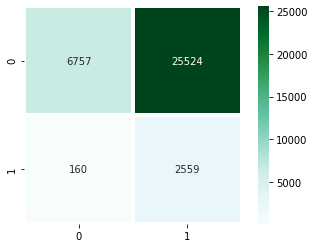

In [ ]:
sns.heatmap(metrics.confusion_matrix(df_model.VIP,df_model.Deposit_Amount>0) , square=True, annot=True, fmt='d', cmap = 'BuGn', linewidths=3);

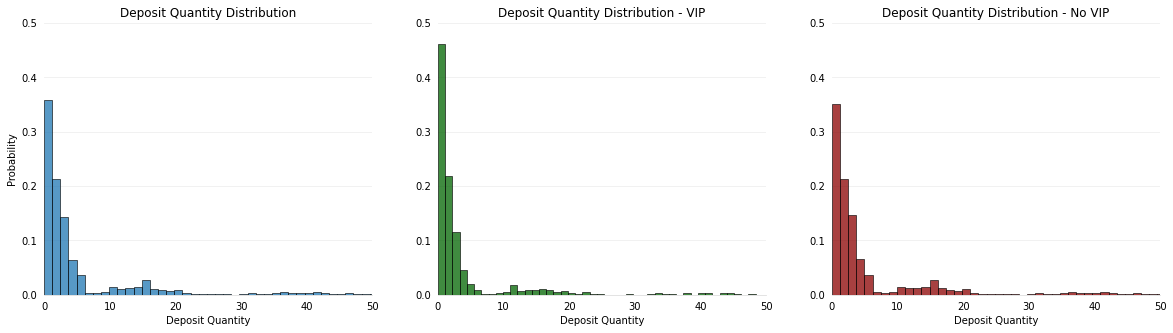

In [ ]:
f,ax=plt.subplots(figsize=(20,5))

plt.subplot(1,3, 1)
ax=sns.histplot(df_model.Deposit_Quantity, bins=50,stat="probability")
ax.set_xlim(0,50)
ax.set_ylim(0,0.5)
ax.set_title('Deposit Quantity Distribution')
ax.set_xlabel('Deposit Quantity')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

plt.subplot(1,3, 2)
ax=sns.histplot(df_model[df_model.VIP==1].Deposit_Quantity, bins=50,color='darkgreen',stat="probability")
ax.set_xlim(0,50)
ax.set_ylim(0,0.5)
ax.set_ylabel(' ')
ax.set_xlabel('Deposit Quantity')
ax.set_title('Deposit Quantity Distribution - VIP')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

plt.subplot(1,3,3)
ax=sns.histplot(df_model[df_model.VIP==0].Deposit_Quantity, bins=50,color='darkred',stat="probability")
ax.set_xlim(0,50)
ax.set_ylim(0,0.5)
ax.set_ylabel(' ')
ax.set_xlabel('Deposit Quantity')
ax.set_title('Deposit Quantity Distribution - No VIP')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

VIP clients are a bit older than Non VIP.

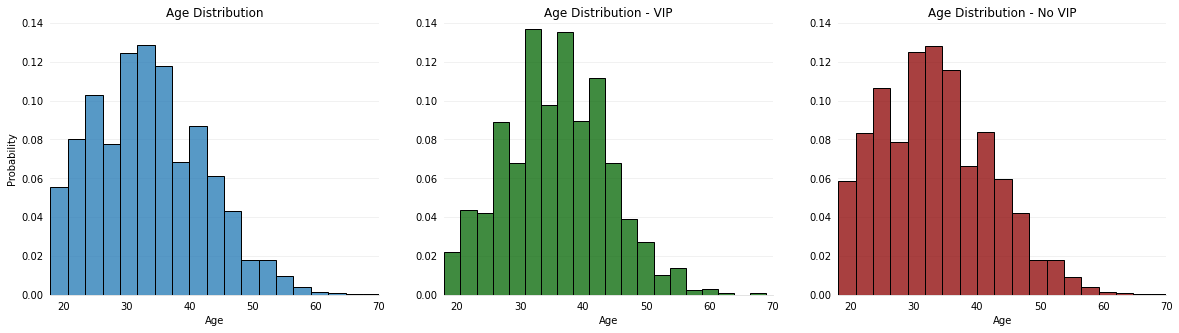

In [ ]:
f,ax=plt.subplots(figsize=(20,5))

plt.subplot(1,3, 1)
ax=sns.histplot(df_model.Age, bins=20,stat="probability")
ax.set_xlim(18,70)
ax.set_ylim(0,0.14)
ax.set_title('Age Distribution')
ax.set_xlabel('Age')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

plt.subplot(1,3, 2)
ax=sns.histplot(df_model[df_model.VIP==1].Age, bins=20,color='darkgreen',stat="probability")
ax.set_xlim(18,70)
ax.set_ylim(0,0.14)
ax.set_ylabel(' ')
ax.set_xlabel('Age')
ax.set_title('Age Distribution - VIP')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

plt.subplot(1,3,3)
ax=sns.histplot(df_model[df_model.VIP==0].Age, bins=20,color='darkred',stat="probability")
ax.set_xlim(18,70)
ax.set_ylim(0,0.14)
ax.set_ylabel(' ')
ax.set_xlabel('Age')
ax.set_title('Age Distribution - No VIP')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')
ax.tick_params(bottom=False, left=False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color='#EEEEEE')
ax.xaxis.grid(False);

In [ ]:
print('Age - No VIP:')
print(df_model[df_model.VIP==0].Age.describe())
print(' ')
print('Age - VIP:')
print(df_model[df_model.VIP==1].Age.describe())

Age - No VIP:
count    31950.000000
mean        33.258091
std          8.749293
min         18.000000
25%         27.000000
50%         33.000000
75%         39.000000
max         73.000000
Name: Age, dtype: float64
 
Age - VIP:
count    2691.000000
mean       35.746191
std         8.098548
min        18.000000
25%        30.000000
50%        36.000000
75%        41.000000
max        69.000000
Name: Age, dtype: float64


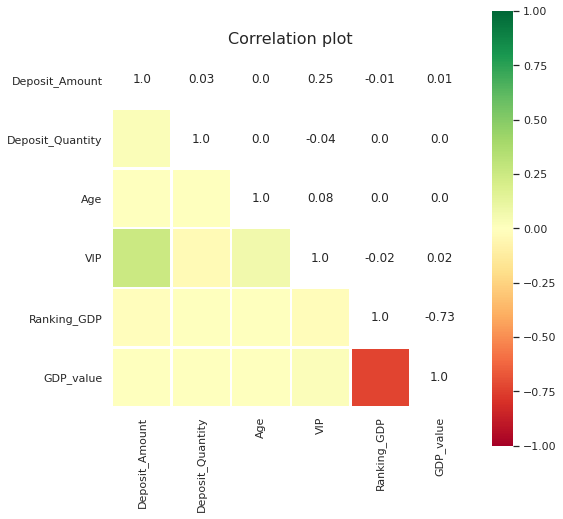

In [ ]:
  sns.set(style="white")
  fig, ax = plt.subplots(1, figsize=(8, 8))
  corr = df_model.corr()
  labels = corr.where(np.triu(np.ones(corr.shape)).astype(np.bool))
  labels = labels.round(2)
  labels = labels.replace(np.nan, ' ', regex=True)

  mask = np.triu(np.ones(corr.shape)).astype(np.bool)
  ax = sns.heatmap(
      corr,
      mask=mask,
      vmin=-1,
      vmax=1,
      center=0,
      cmap='RdYlGn',
      fmt='',
      square=True,
      linewidths=1.5).set_title("Correlation plot", fontsize=16)
  mask = np.ones(corr.shape) - mask
  ax = sns.heatmap(
      corr,
      mask=mask,
      vmin=-1,
      vmax=1,
      center=0,
      cmap=ListedColormap(['white']),
      annot=labels,
      cbar=False,
      fmt='',
      linewidths=1.5)

There is a high correlation between Ranking_GDP and GDP_value, so Ranking_GDP was deleted because the relation with the VIP players is inverse (when the ranking increase the % of vip players decrease, this is worse for the interpretation).

There is a medium correlation between been VIP and the deposit amount, also, there is a small correlation between the VIP and age. Finally, there is a very small correlation between GDP and VIP.

# **3 Data pre-processing**
Train, test, standarization and get dummies variables.

### **3.1 Train - test split**
Modelling data set was split in two disjoint subset: training data set (to identify the best model) and testing data set (to check if the model is expanding the result properly). The sample was getting considering the Deposit_Method.

In [ ]:
X=df_model.drop(columns=['VIP'])
y=df_model['VIP']

In [ ]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, random_state=0,test_size =0.2, stratify=X.Deposit_Method)

### **3.2 Encoding categorical variables**
**Target Encoding**
Country code and deposit method have more or less 200 categories.

In [ ]:
train = Xtrain
train['VIP'] = y
Deposit_Method_dict = dict(train.groupby(["Deposit_Method"])["VIP"].mean())
Country_code_dict = dict(train.groupby(["Country_code"])["VIP"].mean())

In [ ]:
Xtrain["Deposit_Method_encoded"] = Xtrain.Deposit_Method.map(Deposit_Method_dict)
Xtrain["Country_code_encoded"] = Xtrain.Country_code.map(Country_code_dict)

**One hot Encoding**

In [ ]:
Xtrain[['Alert_Type_All_Deposit','Alert_Type_First_Deposit','Alert_Type_Re_deposit','Alert_Type_Sign_Up','Alert_Type_Special']]=\
pd.get_dummies(Xtrain.Dim_Alert_Type_Desc)[['All Deposit','First_Deposit','Re-deposit','Sign Up','Special']]

In [ ]:
Xtrain['Alert_Type_redeposit_special_all']=Xtrain['Alert_Type_All_Deposit']+Xtrain['Alert_Type_Re_deposit']+Xtrain['Alert_Type_Special']
Xtrain['Alert_Type_first_signup']=Xtrain['Alert_Type_Sign_Up']+Xtrain['Alert_Type_First_Deposit']

Drop columns that are not going to be used to train the model.

In [ ]:
Xtrain.drop(columns=['Deposit_Method','Country_code','Country_name','Gender','Dim_Alert_Type_Desc','Ranking_GDP','VIP','Gender',
                     'Alert_Type_All_Deposit','Alert_Type_First_Deposit','Alert_Type_Re_deposit','Alert_Type_Sign_Up',
                     'Alert_Type_Special'],inplace=True)

In [ ]:
Xtrain.head()

,Deposit_Amount,Deposit_Quantity,Age,GDP_value,Deposit_Method_encoded,Country_code_encoded,Alert_Type_redeposit_special_all,Alert_Type_first_signup
7550,9052.603657,5,35.0,1554.0,0.039326,0.067568,1,0
30486,48.114610,1,34.0,5765.0,0.048780,0.079137,0,0
7845,0.000000,0,19.0,1535.0,0.064516,0.084507,1,0
20851,43.358977,2,25.0,5765.0,0.107843,0.069231,0,0
6203,41.703943,3,36.0,7894.0,0.078313,0.078947,0,1


Replicate for Xtest

In [ ]:
Xtest["Deposit_Method_encoded"] = Xtest.Deposit_Method.map(Deposit_Method_dict)
Xtest["Country_code_encoded"] = Xtest.Country_code.map(Country_code_dict)

In [ ]:
Xtest[['Alert_Type_All_Deposit','Alert_Type_First_Deposit','Alert_Type_Re_deposit','Alert_Type_Sign_Up','Alert_Type_Special']]=\
pd.get_dummies(Xtest.Dim_Alert_Type_Desc)[['All Deposit','First_Deposit','Re-deposit','Sign Up','Special']]

In [ ]:
Xtest['Alert_Type_redeposit_special_all']=Xtest['Alert_Type_All_Deposit']+Xtest['Alert_Type_Re_deposit']+Xtest['Alert_Type_Special']
Xtest['Alert_Type_first_signup']=Xtest['Alert_Type_Sign_Up']+Xtest['Alert_Type_First_Deposit']

In [ ]:
Xtest.drop(columns=['Deposit_Method','Country_code','Country_name','Gender','Dim_Alert_Type_Desc','Ranking_GDP','Gender',
                     'Alert_Type_All_Deposit','Alert_Type_First_Deposit','Alert_Type_Re_deposit','Alert_Type_Sign_Up',
                    'Alert_Type_Special'],inplace=True)

In [ ]:
Xtest.head()

,Deposit_Amount,Deposit_Quantity,Age,GDP_value,Deposit_Method_encoded,Country_code_encoded,Alert_Type_redeposit_special_all,Alert_Type_first_signup
5560,55.700181,1,34.0,5765.0,0.125000,0.181159,0,1
9098,31.418342,1,25.0,5765.0,0.093750,0.144928,1,0
19033,64.442176,2,37.0,15166.0,0.052941,0.071895,0,1
23016,47.228790,1,39.0,32038.0,0.049180,0.100000,0,0
7953,43.442327,1,23.0,5765.0,0.049180,0.104895,1,0


Save data from Target Encoding

In [ ]:
with open(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs/Deposit_Method_dict.pkl', 'wb') as f:
    pickle.dump(Deposit_Method_dict, f)

with open(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs/Country_code_dict.pkl', 'wb') as f:
    pickle.dump(Country_code_dict, f)

### **3.3 Fill numerical na values**

In [ ]:
mean_age=Xtrain.Age.mean()
Xtrain['Age']=Xtrain.Age.fillna(mean_age)

NameError: name 'Xtrain' is not defined

Replicate for Xtest

In [ ]:
Xtest['Age']=Xtest.Age.fillna(mean_age)

Save data from training set - Age mean

In [ ]:
with open(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs/mean_age.pkl', 'wb') as f:
    pickle.dump(mean_age, f)

### **3.4. Outlier detection**

In [ ]:
count_outliers=pd.DataFrame(columns=['Outliers','inferior','superior','Maximum'])
# outlier detections:
for col in Xtrain.columns:
    if Xtrain[col].dtypes.name in ('datetime64[ns]','datetime32[ns]','bool','object'):
        pass
    else:
        Q1 = Xtrain[col].quantile(0.25)
        Q3 = Xtrain[col].quantile(0.75)
        IQR = Q3 - Q1
        count_outliers.loc[col] = [((Xtrain[col] < (Q1 - 1.5 * IQR)) | (Xtrain[col] > (Q3 + 1.5 * IQR))).sum(axis=0),
                                   Q1 - 1.5 * IQR,
                                   Q3 + 1.5 * IQR,
                                   Xtrain[col].max()]

In [ ]:
count_outliers[(count_outliers.Outliers>0)&(count_outliers.Maximum>count_outliers.superior+1)&(count_outliers.Maximum>50)]

,Outliers,inferior,superior,Maximum
Deposit_Amount,807.0,-14.296519,100.276392,10085.205071
Deposit_Quantity,4894.0,-3.500000,8.500000,61.000000
Age,148.0,9.000000,57.000000,72.000000
GDP_value,3705.0,-12141.000000,30267.000000,105280.000000


In [ ]:
count_outliers.loc['Deposit_Amount']['superior']

100.27639159840211

In [ ]:
Xtrain['GDP_value']=np.where(Xtrain['GDP_value']>
                             count_outliers.loc['GDP_value']['superior'],count_outliers.loc['GDP_value']['superior'],Xtrain['GDP_value'])
Xtrain['Deposit_Amount']=np.where(Xtrain['Deposit_Amount']>
                                  count_outliers.loc['Deposit_Amount']['superior'],count_outliers.loc['Deposit_Amount']['superior'],Xtrain['Deposit_Amount'])
Xtrain['Deposit_Quantity']=np.where(Xtrain['Deposit_Quantity']>
                                  count_outliers.loc['Deposit_Quantity']['superior'],count_outliers.loc['Deposit_Quantity']['superior'],Xtrain['Deposit_Quantity'])

Replicate for Xtest

In [ ]:
Xtest['GDP_value']=np.where(Xtest['GDP_value']>
                             count_outliers.loc['GDP_value']['superior'],count_outliers.loc['GDP_value']['superior'],Xtest['GDP_value'])
Xtest['Deposit_Amount']=np.where(Xtest['Deposit_Amount']>
                                  count_outliers.loc['Deposit_Amount']['superior'],count_outliers.loc['Deposit_Amount']['superior'],Xtest['Deposit_Amount'])
Xtest['Deposit_Quantity']=np.where(Xtest['Deposit_Quantity']>
                                  count_outliers.loc['Deposit_Quantity']['superior'],count_outliers.loc['Deposit_Quantity']['superior'],Xtest['Deposit_Quantity'])

Save data from outlier outputs - target encoding

In [ ]:
with open(os.path.join(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs', 'count_outliers.pkl'), 'wb') as f:
    pickle.dump(count_outliers, f)

### **3.5 Create and transform numeric variables**

In [ ]:
Xtrain['Deposit_dummy']=np.where(Xtrain['Deposit_Amount']>0,1,0)
Xtrain['Deposit_Amount_sqrt']=np.sqrt(Xtrain['Deposit_Amount'])
Xtrain['Deposit_Quantity_sqrt']=np.sqrt(Xtrain['Deposit_Quantity'])

Xtrain.drop(columns=['Deposit_Amount','Deposit_Quantity'],inplace=True)

Replicate for Xtest

In [ ]:
Xtest['Deposit_dummy']=np.where(Xtest['Deposit_Amount']>0,1,0)
Xtest['Deposit_Amount_sqrt']=np.sqrt(Xtest['Deposit_Amount'])
Xtest['Deposit_Quantity_sqrt']=np.sqrt(Xtest['Deposit_Quantity'])

Xtest.drop(columns=['Deposit_Amount','Deposit_Quantity'],inplace=True)

### **3.6 Data standarization**

In [ ]:
train_columns=list(Xtrain.columns)

In [ ]:
scaler = StandardScaler()
Xtrain=scaler.fit_transform(Xtrain)

Replicate for Xtest

In [ ]:
Xtest=scaler.transform(Xtest)

Save the standarization


In [ ]:
with open(os.path.join(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs', 'scaler_interest.pkl'), 'wb') as f:
    pickle.dump(scaler, f)

with open(os.path.join(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs', 'train_columns.pkl'), 'wb') as f:
    pickle.dump(train_columns, f)

# **4. Model selection - Classification Analysis**

## **4.1 Baseline**
A fundamental aspect of a model assessment is to compare with a baseline. In this case VIP players were simulated according to the probability of being a VIP in the training data.

In [ ]:
baseline_acc=[]
baseline_f1=[]
for i in range(1000):
  sim_baseline=np.random.binomial(size=len(ytest), n=1, p= ytrain.mean())
  baseline_acc.append(round(metrics.accuracy_score(ytest, sim_baseline),3))
  baseline_f1.append(round(metrics.f1_score(ytest, sim_baseline),3))

**Baseline log loss**

In [ ]:
round(metrics.roc_auc_score(ytest,  [ytrain.mean()]*len(ytest)),3)

0.5

In [ ]:
metrics.log_loss(y_true=ytest, y_pred=[ytrain.mean()]*len(ytest))

0.2770491893604383

In [ ]:
baseline=pd.DataFrame(baseline_acc)
baseline.columns=['Accuracy']
baseline['F1']=baseline_f1

In [ ]:
baseline.describe()

,Accuracy,F1
count,1000.000000,1000.000000
mean,0.855724,0.078108
std,0.003203,0.011472
min,0.845000,0.044000
25%,0.854000,0.070000
50%,0.856000,0.078000
75%,0.858000,0.085000
max,0.867000,0.118000


## **4.2 Classification Techniques**


###**4.2.1 Logistic Regression**

Train the model:

In [ ]:

with open("gdrive/My Drive/gamblingCompany - Data Scientist/Outputs/logistic_regression.pkl", "rb") as fp:
   grid_lr = pickle.load(fp)
"""

penalty = ['l1', 'l2']
C = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
class_weight = [ {1:0.70, 0:0.30}, {1:0.60, 0:0.40}
                , {1:0.50, 0:0.50}, {1:0.40, 0:0.60}]

solver = ['liblinear', 'saga'] # it can be used with l1 and l2

param_grid = dict(penalty=penalty,
                  C=C,
                  class_weight=class_weight,
                  solver=solver)

#https://scikit-learn.org/stable/modules/model_evaluation.html
grid_lr = GridSearchCV(estimator=LogisticRegression(),
                    param_grid=param_grid,
                    scoring='neg_log_loss',
                    cv = 3, verbose=2, n_jobs = -1)

#Fit the model
grid_lr = grid_lr.fit(Xtrain, ytrain)
"""

"\n\npenalty = ['l1', 'l2']\nC = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]\nclass_weight = [ {1:0.70, 0:0.30}, {1:0.60, 0:0.40}\n                , {1:0.50, 0:0.50}, {1:0.40, 0:0.60}]\n\nsolver = ['liblinear', 'saga'] # it can be used with l1 and l2\n\nparam_grid = dict(penalty=penalty,\n                  C=C,\n                  class_weight=class_weight,\n                  solver=solver)\n\n#https://scikit-learn.org/stable/modules/model_evaluation.html\ngrid_lr = GridSearchCV(estimator=LogisticRegression(),\n                    param_grid=param_grid,\n                    scoring='neg_log_loss',\n                    cv = 3, verbose=2, n_jobs = -1) \n\n#Fit the model\ngrid_lr = grid_lr.fit(Xtrain, ytrain)\n"

In [ ]:
#predict
#ypred = grid_lr.predict(Xtest)

yproba = grid_lr.predict_proba(Xtest)[:,1]

grid_lr.best_params_

{'C': 1, 'class_weight': {0: 0.5, 1: 0.5}, 'penalty': 'l1', 'solver': 'saga'}

In [ ]:
params=grid_lr.best_params_
best_lr=LogisticRegression(C=params['C'],class_weight=params['class_weight'],penalty=params['penalty'],solver=params['solver']).fit(Xtrain, ytrain)

In [ ]:
coefficients=pd.DataFrame(train_columns,columns=['variables'])
coefficients['coeff']=list(best_lr.coef_[0])

Training metrics:

In [ ]:
yproba_train = grid_lr.predict_proba(Xtrain)[:,1]
yest_train = np.where(yproba_train>Find_Optimal_Cutoff(ytrain,yproba_train)[0],1,0)
print("Accuracy train set: ", round(metrics.accuracy_score(ytrain, yest_train),3))
print("F1 Score train set: ", round(metrics.f1_score(ytrain, yest_train),3))
print("AUC train set: ", round(metrics.roc_auc_score(ytrain, yproba_train),3))
print("Log Loss train set: ",round(metrics.log_loss(ytrain,yproba_train),3))

Test Metrics:

In [ ]:
skplt.metrics.plot_roc(ytest, grid_lr.predict_proba(Xtest),title='ROC Curve',plot_micro=False,classes_to_plot=1,plot_macro=False);

In [ ]:
ypred=np.where(yproba>Find_Optimal_Cutoff(ytrain,yproba_train)[0],1,0)

In [ ]:
sns.set(style="white")
# confusion matrix
cnf_matrix = metrics.confusion_matrix(ytest, ypred)
np.set_printoptions(precision=2)

# chart
plt.figure(figsize=(5,5))
plot_confusion_matrix(cnf_matrix, classes=['No VIP','VIP'],
                      title='Confusion Matrix')

# measures :
tn, fp, fn, tp = cnf_matrix.ravel()
print("Accuracy test set: ", round(metrics.accuracy_score(ytest, ypred),3))
print("F1 Score test set: ", round(metrics.f1_score(ytest, ypred),3))
print("AUC test set: ", round(metrics.roc_auc_score(ytest, yproba),3))
print("Log Loss test set: ",round(metrics.log_loss(ytest,yproba),3))

### **4.2.2 Decision tree classifier**

Train the model:

In [ ]:

with open("gdrive/My Drive/gamblingCompany - Data Scientist/Outputs/tree_classification.pkl", "rb") as fp:
  tree_best_model = pickle.load(fp)
"""
#List hyperparameters that we want to tune.
criterion = ['gini','entropy']
max_depth = list(range(1,15))
min_samples_leaf=list(range(1,15))
class_weight = [ {1:0.70, 0:0.30}, {1:0.60, 0:0.40}
                , {1:0.50, 0:0.50}, {1:0.40, 0:0.60}, {1:0.30, 0:0.70}]

#Convert to dictionary
hyperparameters = dict(criterion=criterion, max_depth=max_depth, min_samples_leaf=min_samples_leaf,class_weight=class_weight)

#from sklearn.model_selection import GridSearchCV
#Create new KNN object
model_tree = DecisionTreeClassifier()
#Use GridSearch
clf = GridSearchCV(estimator=model_tree,
                         param_grid =hyperparameters,
                         scoring='neg_log_loss',
                         cv = 3, verbose=2,  n_jobs = -1)

#Fit the model
tree_best_model = clf.fit(Xtrain,ytrain)
"""

In [ ]:
#predict
#ypred = tree_best_model.predict(Xtest)
yproba = tree_best_model.predict_proba(Xtest)[:,1]
tree_best_model.best_params_

Training metrics:

In [ ]:
yproba_train = tree_best_model.predict_proba(Xtrain)[:,1]
yest_train = np.where(yproba_train>Find_Optimal_Cutoff(ytrain,yproba_train)[0],1,0)
print("Accuracy train set: ", round(metrics.accuracy_score(ytrain, yest_train),3))
print("F1 Score train set: ", round(metrics.f1_score(ytrain, yest_train),3))
print("AUC train set: ", round(metrics.roc_auc_score(ytrain, yest_train),3))
print("Log Loss train set: ",round(metrics.log_loss(ytrain,yproba_train),3))

Test Metrics:

In [ ]:
skplt.metrics.plot_roc(ytest, tree_best_model.predict_proba(Xtest),title='ROC Curve',plot_micro=False,classes_to_plot=1,plot_macro=False);

In [ ]:
ypred=np.where(yproba>Find_Optimal_Cutoff(ytrain,yproba_train)[0],1,0)

In [ ]:
sns.set(style="white")
# confusion matrix
cnf_matrix = metrics.confusion_matrix(ytest, ypred)
np.set_printoptions(precision=2)

# chart
plt.figure(figsize=(5,5))
plot_confusion_matrix(cnf_matrix, classes=['No VIP','VIP'],
                      title='Confusion Matrix')

# measures :
tn, fp, fn, tp = cnf_matrix.ravel()
print("Accuracy test set: ", round(metrics.accuracy_score(ytest, ypred),3))
print("F1 Score test set: ", round(metrics.f1_score(ytest, ypred),3))
print("AUC test set: ", round(metrics.roc_auc_score(ytest, yproba),3))
print("Log Loss test set: ",round(metrics.log_loss(ytest,yproba),3))

### **4.2.3 Random Forest**

Train the model:

In [ ]:
# Number of trees in random forest
n_estimators = [int(x) for x in np.linspace(start = 50, stop = 400, num = 10)]
# Number of features to consider at every split
max_features = ['auto', 'sqrt']
# Maximum number of levels in tree
max_depth = list(range(3,12))
max_depth.append(None)
# Minimum number of samples required to split a node
min_samples_split = [2, 5, 10, 20]
# Minimum number of samples required at each leaf node
min_samples_leaf=list(range(1,15))
# Method of selecting samples for training each tree
bootstrap = [True, False]

class_weight = [ {1:0.70, 0:0.30}, {1:0.60, 0:0.40}
                , {1:0.50, 0:0.50}, {1:0.40, 0:0.60}, {1:0.30, 0:0.70}]

# Create the random grid
hyperparameters = {'n_estimators': n_estimators,
               'max_features': max_features,
               'max_depth': max_depth,
               'min_samples_split': min_samples_split,
               'min_samples_leaf': min_samples_leaf,
               'bootstrap': bootstrap,
               'class_weight':class_weight}

In [ ]:
with open("gdrive/My Drive/gamblingCompany - Data Scientist/Outputs/rf_classification.pkl", "rb") as fp:
   rf_best_model = pickle.load(fp)

"""
# First create the base model to tune
rf = RandomForestClassifier()
# Random search of parameters, using 3 fold cross validation,
# search across 100 different combinations, and use all available cores
rf_best_model = RandomizedSearchCV(estimator = rf,
                               param_distributions = hyperparameters,
                               scoring='neg_log_loss',
                               n_iter = 100, cv = 3, verbose=4,
                               random_state=42, n_jobs = -1)

# Fit the random search model
rf_best_model.fit(Xtrain, ytrain)
"""

In [ ]:
#ypred = rf_best_model.predict(Xtest)
yproba = rf_best_model.predict_proba(Xtest)[:,1]
rf_best_model.best_params_

In [ ]:
Find_Optimal_Cutoff(ytest,yproba)[0]

Training metrics:

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

feature_importance_chart=pd.DataFrame(train_columns,columns=['variables'])
feature_importance_chart['importance']=rf_best_model.best_estimator_.feature_importances_.tolist()
feature_importance_chart=feature_importance_chart.sort_values(by='importance',ascending=False)

sns.barplot(y=feature_importance_chart['variables'], x=feature_importance_chart['importance'],color=colors[5]);
plt.xlim(0,0.45)
plt.title("Feature Importance - Random Forest")
plt.ylabel("")
plt.xlabel("Importance")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#DDDDDD')

# Second, remove the ticks as well.
ax.tick_params(bottom=False, left=False)

# Third, add a horizontal grid (but keep the vertical grid hidden).
# Color the lines a light gray as well.
ax.set_axisbelow(True)
ax.xaxis.grid(True, color='#EEEEEE')
ax.yaxis.grid(False);

In [ ]:
yproba_train = rf_best_model.predict_proba(Xtrain)[:,1]
yest_train = np.where(yproba_train>Find_Optimal_Cutoff(ytrain,yproba_train)[0],1,0)
print("Accuracy train set: ", round(metrics.accuracy_score(ytrain, yest_train),3))
print("F1 Score train set: ", round(metrics.f1_score(ytrain, yest_train),3))
print("AUC train set: ", round(metrics.roc_auc_score(ytrain, yproba_train),3))
print("Log Loss train set: ",round(metrics.log_loss(ytrain,yproba_train),3))

In [ ]:
skplt.metrics.plot_roc(ytrain, rf_best_model.predict_proba(Xtrain),title='ROC Curve',plot_micro=False,classes_to_plot=1,plot_macro=False);

In [ ]:
with open(os.path.join(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs', 'optimal_cutoff.pkl'), 'wb') as f:
    pickle.dump(Find_Optimal_Cutoff(ytrain,yproba_train)[0], f)

Test Metrics:

In [ ]:
skplt.metrics.plot_roc(ytest, rf_best_model.predict_proba(Xtest),title='ROC Curve',plot_micro=False,classes_to_plot=1,plot_macro=False);

In [ ]:
ypred=np.where(yproba>Find_Optimal_Cutoff(ytrain,yproba_train)[0],1,0)

In [ ]:
sns.set(style="white")
# confusion matrix
cnf_matrix = metrics.confusion_matrix(ytest, ypred)
np.set_printoptions(precision=2)

# chart
plt.figure(figsize=(5,5))
plot_confusion_matrix(cnf_matrix, classes=['No VIP','VIP'],
                      title='Confusion Matrix')


tn, fp, fn, tp = cnf_matrix.ravel()
# Measures :
print("Accuracy test set: ", round(metrics.accuracy_score(ytest, ypred),3))
print("F1 Score test set: ", round(metrics.f1_score(ytest, ypred),3))
print("AUC test set: ", round(metrics.roc_auc_score(ytest, yproba),3))
print("Log Loss test set: ",round(metrics.log_loss(ytest,yproba),3))

In [ ]:
(1670+369)/len(ytest)

In [ ]:
(186+369)/len(ytest)

In [ ]:
plt.figure(figsize=(5,5))

plot_confusion_matrix(metrics.confusion_matrix(ytest, ypred,normalize='true'), classes=['No VIP','VIP'],
                      title='Confusion Matrix - Normalized',
                      normalize=True)

Comparison between train and test results




In [ ]:
# Libraries
import matplotlib.pyplot as plt
import pandas as pd
from math import pi

# Set data
df = pd.DataFrame({
'group': ['Train','Test'],
'Log Loss': [round(metrics.log_loss(ytrain,yproba_train),3), round(metrics.log_loss(ytest,yproba),3)],
'Accuracy': [round(metrics.accuracy_score(ytrain, yest_train),3), round(metrics.accuracy_score(ytest, ypred),3)],
'AUC': [round(metrics.roc_auc_score(ytrain, yproba_train),3), round(metrics.roc_auc_score(ytest, yproba),3)],
'F1 Score': [round(metrics.f1_score(ytrain, yest_train),3), round(metrics.f1_score(ytest, ypred),3)]
})

# ------- PART 1: Create background

# number of variable
categories=list(df)[1:]
N = len(categories)

# What will be the angle of each axis in the plot? (we divide the plot / number of variable)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]


plt.figure(figsize=(6,6))
# Initialise the spider plot
ax = plt.subplot(111, polar=True)

# If you want the first axis to be on top:
ax.set_theta_offset(pi / 2)
ax.set_theta_direction(-1)


# Draw one axe per variable + add labels
plt.xticks(angles[:-1], categories)

# Draw ylabels
ax.set_rlabel_position(0)
plt.yticks([0.2,0.4,0.6,0.8], ["0.2","0.4","0.6","0.8"], color="grey", size=12)
plt.ylim(0,0.9)


# ------- PART 2: Add plots

# Plot each individual = each line of the data
# I don't make a loop, because plotting more than 3 groups makes the chart unreadable

# Ind1
values=df.loc[0].drop('group').values.flatten().tolist()
values += values[:1]
ax.plot(angles, values, linewidth=3, linestyle='solid', label="Train",color=colors[2])
ax.fill(angles, values, 'b', alpha=0)

# Ind2
values=df.loc[1].drop('group').values.flatten().tolist()
values += values[:1]
ax.plot(angles, values, linewidth=3, linestyle='solid', label="Test", color=colors[5])
ax.fill(angles, values, 'r', alpha=0)

# Add legend
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.title("Train vs Test metrics", fontsize=16, pad=20)
# Show the graph
plt.show()

### **4.2.4 XgBoost**

Train the model:

In [ ]:

with open("gdrive/My Drive/gamblingCompany - Data Scientist/Outputs/xgboost_classification.pkl", "rb") as fp:
   xgb_best_model = pickle.load(fp)

"""
model_xgb = xgb.XGBClassifier(n_jobs=-1)

one_to_left = st.beta(10, 1) #  this distribution give us values between 0 and 1, closely to 1

max_depth = list(range(3,12))
max_depth.append(None)

hyperparameters = {
    "n_estimators": st.randint(50,400), # Number of boosted trees to fit.
    "max_depth": max_depth,     # Maximum tree depth for base learners.
    "learning_rate": st.uniform(0.05, 0.4), # Boosting learning rate (xgb’s “eta”)
    "colsample_bytree": one_to_left, # Subsample ratio of columns when constructing each tree.
    "subsample": one_to_left,     # Subsample ratio of the training instance.
    "gamma": st.uniform(0, 10), # Minimum loss reduction required to make a further partition on a leaf node of the tree.
    'reg_alpha': st.uniform(0.05,10),   # L1 regularization term on weights
    "min_child_weight": st.uniform(1,20), # Minimum sum of instance weight(hessian) needed in a child.
    'class_weight':[ {1:0.70, 0:0.30}, {1:0.60, 0:0.40}
                   , {1:0.50, 0:0.50}, {1:0.40, 0:0.60}, {1:0.30, 0:0.70}]
}

xgb_best_model = RandomizedSearchCV(estimator = model_xgb,
                            param_distributions = hyperparameters,
                            scoring='balanced_accuracy',
                            n_iter = 100, cv = 3, verbose=4,
                            random_state=42, n_jobs = -1)
xgb_best_model.fit(Xtrain, ytrain)
"""

In [ ]:
#ypred = xgb_best_model.predict(Xtest)
yproba = xgb_best_model.predict_proba(Xtest)[:,1]
xgb_best_model.best_params_

In [ ]:
Find_Optimal_Cutoff(ytrain,yproba_train)

Training metrics:

In [ ]:
yproba_train = xgb_best_model.predict_proba(Xtrain)[:,1]
yest_train = np.where(yproba_train>Find_Optimal_Cutoff(ytrain,yproba_train)[0],1,0)
print("Accuracy train set: ", round(metrics.accuracy_score(ytrain, yest_train),3))
print("F1 Score train set: ", round(metrics.f1_score(ytrain, yest_train),3))
print("AUC train set: ", round(metrics.roc_auc_score(ytrain, yproba_train),3))
print("Log Loss train set: ",round(metrics.log_loss(ytrain,yproba_train),3))

In [ ]:
ypred=np.where(yproba>Find_Optimal_Cutoff(ytrain,yproba_train)[0],1,0)

Test Metrics:

In [ ]:
skplt.metrics.plot_roc(ytest, xgb_best_model.predict_proba(Xtest),title='ROC Curve',plot_micro=False,classes_to_plot=1,plot_macro=False);

In [ ]:
sns.set(style="white")
# confusion matrix
cnf_matrix = metrics.confusion_matrix(ytest, ypred)
np.set_printoptions(precision=2)

# chart
plt.figure(figsize=(5,5))
plot_confusion_matrix(cnf_matrix, classes=['No VIP','VIP'],
                      title='Confusion Matrix')

# Measures :
tn, fp, fn, tp = cnf_matrix.ravel()

print("Accuracy test set: ", round(metrics.accuracy_score(ytest, ypred),3))
print("F1 Score test set: ", round(metrics.f1_score(ytest, ypred),3))
print("AUC test set: ", round(metrics.roc_auc_score(ytest, yproba),3))
print("Log Loss test set: ",round(metrics.log_loss(ytest,yproba),3))

## **4.3 Final Model Selection and conclusions**
For compare performance metric in each model, the following table was built:

| **Metric** | **Baseline** |  **Logistic** | **Tree** | **Random Forest** | **XgBoost** |
|--|:-:|:-:|:-:|:-:|:-:|
| **Log Loss**|  0.277 | 0.245 |	0.254 |	**0.240** |	0.250 |
| **Accuracy** | 0.856 |  0.700 | **0.875** | 0.703 | 0.763 |
| **F1 Score** |  0.078 | 0.256 | **0.297** | 0.285 | 0.282  |
| **AUC** |  0.500 | 0.750 | 0.693 | **0.765** | 0.745  |

Comparing the results among different techniques, Random Forest gives the best results based on log loss. On the other hand, decission tree classifier ends up with the best F1 score and accuracy.

All the models perform better than the baseline in terms of F1 score, AUC and Log Loss. However, the accuracy in the baseline is only surpassed by the classification regression tree, this is because 93% of our customers are NoN VIP, so the baseline tends to predict most of the customers as NoN VIP (majority class).

In order to improve the model's output we should consider the cost of classify a VIP as NoN VIP (lost the opportunity of send the specific offer) and the cost of classify a NoN VIP customer as VIP (lost money sending the offer to someone with low CLV). This could be achived estimating the expected earning per VIP customer and the expected earning/lost per NoN VIP customer

Save models:

In [ ]:
#Save models
with open(os.path.join(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs', 'logistic_regression.pkl'), 'wb') as f:
    pickle.dump(grid_lr, f)
with open(os.path.join(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs', 'tree_classification.pkl'), 'wb') as f:
    pickle.dump(tree_best_model, f)
with open(os.path.join(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs', 'rf_classification.pkl'), 'wb') as f:
    pickle.dump(rf_best_model, f)
with open(os.path.join(r'gdrive/My Drive/gamblingCompany - Data Scientist/Outputs', 'xgboost_classification.pkl'), 'wb') as f:
    pickle.dump(xgb_best_model, f)

# **5. Deploy the model**
Apply the model in the deliverable data set

In [ ]:
#read deploy data
path = r'gdrive/My Drive/gamblingCompany - Data Scientist/' # path
df_deploy = pd.read_csv(path+'Data/VIP_Test.csv', na_values='?')

player_id = pd.DataFrame(df_deploy.Player_Id)
df_deploy.drop(columns=['Player_Id'],inplace=True)

#Fill NAs
df_deploy.Gender.fillna('NaN', inplace=True)
df_deploy.Dim_Alert_Type_Desc.fillna('NaN', inplace=True)
df_deploy.Country.fillna('NaN', inplace=True)
df_deploy.Deposit_Method.fillna('NaN', inplace=True)

# read external files
with open(path+'Outputs/Country_codes.pkl', 'rb') as fp:
    Country_codes = pickle.load(fp)

with open(path+'Outputs/GDP.pkl', 'rb') as fp:
    GDP = pickle.load(fp)

#join external final to deploy model
df_deploy = pd.merge(df_deploy,Country_codes,  how='left', left_on=['Country'], right_on = ['Code'])
df_deploy.rename(columns={'Country':'Country_code'}, inplace=True)
df_deploy.drop(columns=['Code'],inplace=True)
df_deploy = pd.merge(df_deploy, GDP,  how='left', left_on=['Country_name'], right_on = ['Country_name'])

#fill NAs
df_deploy.GDP_value.fillna((GDP.GDP_value.median()),inplace=True)
df_deploy.Ranking_GDP.fillna((round(GDP.Ranking_GDP.median(),0)),inplace=True)

# read target encoding files
with open(path+'Outputs/Deposit_Method_dict.pkl', "rb") as fp:
   Deposit_Method_dict = pickle.load(fp)

with open(path+"Outputs/Country_code_dict.pkl", "rb") as fp:
   Country_code_dict = pickle.load(fp)

#apply target encoder dictionaries
df_deploy["Deposit_Method_encoded"] = df_deploy.Deposit_Method.map(Deposit_Method_dict)
df_deploy["Country_code_encoded"] = df_deploy.Country_code.map(Country_code_dict)

#Get dummies
df_deploy[['Alert_Type_All_Deposit','Alert_Type_First_Deposit','Alert_Type_Re_deposit','Alert_Type_Sign_Up','Alert_Type_Special']]=\
pd.get_dummies(df_deploy.Dim_Alert_Type_Desc)[['All Deposit','First_Deposit','Re-deposit','Sign Up','Special']]

df_deploy['Alert_Type_redeposit_special_all']=df_deploy['Alert_Type_All_Deposit']+df_deploy['Alert_Type_Re_deposit']+df_deploy['Alert_Type_Special']
df_deploy['Alert_Type_first_signup']=df_deploy['Alert_Type_Sign_Up']+df_deploy['Alert_Type_First_Deposit']

#drop unuseful columns
df_deploy.drop(columns=['Deposit_Method','Country_code','Country_name','Gender','Dim_Alert_Type_Desc','Ranking_GDP','VIP',
                     'Gender','Alert_Type_All_Deposit','Alert_Type_First_Deposit','Alert_Type_Re_deposit',
                     'Alert_Type_Sign_Up','Alert_Type_Special'],inplace=True)

#fill NAs - Age
with open(path+'Outputs/mean_age.pkl', "rb") as fp:
   mean_age = pickle.load(fp)
df_deploy['Age']=df_deploy.Age.fillna(mean_age)

#read outlier's thresholds
with open(path+'Outputs/count_outliers.pkl', "rb") as fp:
   count_outliers = pickle.load(fp)

#apply outlier thresholds
df_deploy['GDP_value']=np.where(df_deploy['GDP_value']>
                             count_outliers.loc['GDP_value']['superior'],count_outliers.loc['GDP_value']['superior'],df_deploy['GDP_value'])
df_deploy['Deposit_Amount']=np.where(df_deploy['Deposit_Amount']>
                                  count_outliers.loc['Deposit_Amount']['superior'],count_outliers.loc['Deposit_Amount']['superior'],df_deploy['Deposit_Amount'])
df_deploy['Deposit_Quantity']=np.where(df_deploy['Deposit_Quantity']>
                                  count_outliers.loc['Deposit_Quantity']['superior'],count_outliers.loc['Deposit_Quantity']['superior'],df_deploy['Deposit_Quantity'])

#Transform numerical variables
df_deploy['Deposit_dummy']=np.where(df_deploy['Deposit_Amount']>0,1,0)
df_deploy['Deposit_Amount_sqrt']=np.sqrt(df_deploy['Deposit_Amount'])
df_deploy['Deposit_Quantity_sqrt']=np.sqrt(df_deploy['Deposit_Quantity'])

df_deploy.drop(columns=['Deposit_Amount','Deposit_Quantity'],inplace=True)

#Standarization
with open(path+'Outputs/scaler_interest.pkl', "rb") as fp:
   scaler = pickle.load(fp)

with open(path+'Outputs/train_columns.pkl', "rb") as fp:
   train_columns = pickle.load(fp)

df_deploy=scaler.transform(df_deploy)

#Read final model
with open(path+'Outputs/rf_classification.pkl', "rb") as fp:
   rf_best_model = pickle.load(fp)

#Apply model
yproba = rf_best_model.predict_proba(df_deploy)[:,1]

# read again the deploy dataset to paste the probabilities

final_output = pd.read_csv(path+'Data/VIP_Test.csv', na_values='?')

final_output['VIP']=yproba

#save the file
final_output.to_csv(path+'Data/test_with_probabilities.csv',index=False)

In [ ]:
#with open("gdrive/My Drive/gamblingCompany - Data Scientist/Outputs/optimal_cutoff.pkl", "rb") as fp:
#   optimal_cutoff = pickle.load(fp)


#player_id['model_probability']=yproba

#ypred = np.where(yproba>optimal_cutoff,1,0)
#player_id['model_prediction']=ypred
#player_id.to_csv(r'gdrive/My Drive/gamblingCompany - Data Scientist/Data/test.csv',index=False)